Import Necessary Libraries

In [ ]:
from datetime import datetime
from pathlib import Path
from collections import Counter

import numpy as np
from matplotlib import pyplot as plt
import pandas as pd

import seaborn as sns

from google.colab import drive

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix

import torch
import torch.utils.data as data_utils
import torch.optim as torch_optim
import torch.nn as nn
import torch.nn.functional as F

Set up device to operate on

In [ ]:
device = torch.device('cuda:0') if torch.cuda.is_available() else torch.device('cpu')
device

device(type='cuda', index=0)

Mount Google Drive to configure dataset access

In [ ]:
drive.mount('content/', force_remount = True)

Mounted at content/


In [ ]:
root_dir = 'content/My Drive/'
!ls "$root_dir/csc451"

Assignment_01_skeleton_PyTorch.ipynb  sensor_readings_24.data


In [ ]:
# pointing to the dataset directory on Google Drive
path = root_dir+'/csc451/'

!ls "{path}"

Assignment_01_skeleton_PyTorch.ipynb  sensor_readings_24.data


Load Dataset, Inspect, and Prepare

In [ ]:
df = pd.read_csv(path+'sensor_readings_24.data', header = None, names=[f'feat{idx:02d}' for idx in range(1,25)]+['target'])
print("Shape:", df.shape)
df.head()

Shape: (5456, 25)


,feat01,feat02,feat03,feat04,feat05,feat06,feat07,feat08,feat09,feat10,...,feat16,feat17,feat18,feat19,feat20,feat21,feat22,feat23,feat24,target
0,0.438,0.498,3.625,3.645,5.0,2.918,5.0,2.351,2.332,2.643,...,0.593,0.502,0.493,0.504,0.445,0.431,0.444,0.440,0.429,Slight-Right-Turn
1,0.438,0.498,3.625,3.648,5.0,2.918,5.0,2.637,2.332,2.649,...,0.592,0.502,0.493,0.504,0.449,0.431,0.444,0.443,0.429,Slight-Right-Turn
2,0.438,0.498,3.625,3.629,5.0,2.918,5.0,2.637,2.334,2.643,...,0.593,0.502,0.493,0.504,0.449,0.431,0.444,0.446,0.429,Slight-Right-Turn
3,0.437,0.501,3.625,3.626,5.0,2.918,5.0,2.353,2.334,2.642,...,0.593,0.502,0.493,0.504,0.449,0.431,0.444,0.444,0.429,Slight-Right-Turn
4,0.438,0.498,3.626,3.629,5.0,2.918,5.0,2.640,2.334,2.639,...,0.592,0.502,0.493,0.504,0.449,0.431,0.444,0.441,0.429,Slight-Right-Turn


In [ ]:
# Inspect the label distribution
Counter(df['target'])

Counter({'Slight-Right-Turn': 826,
         'Sharp-Right-Turn': 2097,
         'Move-Forward': 2205,
         'Slight-Left-Turn': 328})

In [ ]:

classnames = list(df['target'].unique())

# to map text labels to numeric (integer encoding)
classname2label = {classname:classnames.index(classname) for classname in classnames}
classname2label

{'Slight-Right-Turn': 0,
 'Sharp-Right-Turn': 1,
 'Move-Forward': 2,
 'Slight-Left-Turn': 3}

In [ ]:
# create and populate numeric label column
df['target_int'] = df['target'].map(classname2label)
df['target_int'].unique()

array([0, 1, 2, 3])

In [ ]:
# verify the inclusion of the new column (numeric labels)
df.head()

,feat01,feat02,feat03,feat04,feat05,feat06,feat07,feat08,feat09,feat10,...,feat17,feat18,feat19,feat20,feat21,feat22,feat23,feat24,target,target_int
0,0.438,0.498,3.625,3.645,5.0,2.918,5.0,2.351,2.332,2.643,...,0.502,0.493,0.504,0.445,0.431,0.444,0.440,0.429,Slight-Right-Turn,0
1,0.438,0.498,3.625,3.648,5.0,2.918,5.0,2.637,2.332,2.649,...,0.502,0.493,0.504,0.449,0.431,0.444,0.443,0.429,Slight-Right-Turn,0
2,0.438,0.498,3.625,3.629,5.0,2.918,5.0,2.637,2.334,2.643,...,0.502,0.493,0.504,0.449,0.431,0.444,0.446,0.429,Slight-Right-Turn,0
3,0.437,0.501,3.625,3.626,5.0,2.918,5.0,2.353,2.334,2.642,...,0.502,0.493,0.504,0.449,0.431,0.444,0.444,0.429,Slight-Right-Turn,0
4,0.438,0.498,3.626,3.629,5.0,2.918,5.0,2.640,2.334,2.639,...,0.502,0.493,0.504,0.449,0.431,0.444,0.441,0.429,Slight-Right-Turn,0


In [ ]:
# leave out the target columns from the input
dataX = df.drop(['target','target_int'], axis = 1)
print('dataset size:',len(dataX))
dataX.head()

dataset size: 5456


,feat01,feat02,feat03,feat04,feat05,feat06,feat07,feat08,feat09,feat10,...,feat15,feat16,feat17,feat18,feat19,feat20,feat21,feat22,feat23,feat24
0,0.438,0.498,3.625,3.645,5.0,2.918,5.0,2.351,2.332,2.643,...,1.744,0.593,0.502,0.493,0.504,0.445,0.431,0.444,0.440,0.429
1,0.438,0.498,3.625,3.648,5.0,2.918,5.0,2.637,2.332,2.649,...,1.744,0.592,0.502,0.493,0.504,0.449,0.431,0.444,0.443,0.429
2,0.438,0.498,3.625,3.629,5.0,2.918,5.0,2.637,2.334,2.643,...,1.744,0.593,0.502,0.493,0.504,0.449,0.431,0.444,0.446,0.429
3,0.437,0.501,3.625,3.626,5.0,2.918,5.0,2.353,2.334,2.642,...,1.744,0.593,0.502,0.493,0.504,0.449,0.431,0.444,0.444,0.429
4,0.438,0.498,3.626,3.629,5.0,2.918,5.0,2.640,2.334,2.639,...,1.744,0.592,0.502,0.493,0.504,0.449,0.431,0.444,0.441,0.429


In [ ]:
# integer-coded data labels
Y = list(df['target_int'].copy())
np.unique(Y), len(Y)

(array([0, 1, 2, 3]), 5456)

In [ ]:
# inspect the label distribution
labeldist = Counter(Y)
tmp = np.array(list(labeldist.values()))
print(tmp)
tmp/sum(tmp)*100

[ 826 2097 2205  328]


array([15.13929619, 38.43475073, 40.41422287,  6.01173021])

In [ ]:
# convert pandas df to numpy ndarray
X = dataX.to_numpy()

# generate train-val and test splits
# TODO (hint: use sklearn's train_test_split() )

X_train, X_temp, Y_train, Y_temp = train_test_split(X,Y, test_size=0.20, stratify=Y, random_state=123)

# generate train and validation splits
# TODO (hint: use sklearn's train_test_split() )

#X_valid,X_test, Y_valid, Y_test = train_test_split(X_temp,Y_temp, test_size=0.50, stratify=Y_temp, random_state=123)
X_val, X_test, Y_val, Y_test = train_test_split(X_temp, Y_temp, test_size=0.50, stratify=Y_temp, random_state=123)

In [ ]:
# verify the ratio of the splits
len(Y_train), len(Y_valid), len(Y_test)

(4364, 546, 546)

Define the Neural Network

In [ ]:
class RobotMoveModel(nn.Module):
    def __init__(self, n_feat, n_out):
        super().__init__()

        # normal (linear) layers
        #self.lin1 = nn.Linear(n_feat, 5)

        #self.lin2 = nn.Linear(5, n_out)

        self.lin1 = nn.Linear(n_feat, 18)#layer 1
        self.lin2 = nn.Linear(18, 12)
        self.lin3 = nn.Linear(12,10)#3
        self.lin4 = nn.Linear(10, n_out)#output#remember matrix multiplcation


    # called during forward propagation
    def forward(self, x):

        #x = F.relu(self.lin1(x))
        #x = self.lin2(x)

        x = F.relu(self.lin1(x))
        x = F.relu(self.lin2(x))
        x = F.relu(self.lin3(x))
        x = self.lin4(x)

        # return the model output
        return x

Core functions

In [ ]:
def get_optimizer(model, lr = 0.001, wd = 0.0):
    # the trainable model parameters
    parameters = filter(lambda p: p.requires_grad, model.parameters())
    # create optimizer (Adam) with passed hyper-parameters
    optim = torch_optim.Adam(parameters, lr=lr, weight_decay=wd)

    return optim

In [ ]:
def get_lr_scheduler(optim, max_lr, steps_per_epoch, epochs):
  # learning rate scheduler (OneCycle) to control the learning rate
  lr_scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer = optim, max_lr = max_lr, steps_per_epoch = steps_per_epoch, epochs = epochs)

  return lr_scheduler

In [ ]:
def train_model(model, optim, loss_fn, lr_scheduler, train_dl):
    # put the model in training mode
    model.train()

    # to keep track of loss
    total = 0
    sum_loss = 0

    # ground truth and predictions
    ys_true = []
    ys_pred = []

    for x, y in train_dl:  # one minibatch
        x, y, = x.to(device), y.to(device)  # move the data to the device being used (CPU/GPU)
        batch_sz = y.shape[0]   # minibatch size (since the last minibatch could be smaller than the others)
        out = model(x.float())  # compute the output of the network (forward propagation)
        loss = loss_fn(out.float(), y.long())   # compute the loss for the minibatch
        optim.zero_grad()   # reset the gradients of the optimizer so that it doesn't accumulate
        loss.backward()     # backpropagation (computes gradients of the loss w.r.t. to model parameters)
        optim.step()        # update the model parameters
        lr_scheduler.step() # update the learning rate according to the schedule
        total += batch_sz   # data points processed so far in the epoch
        sum_loss += batch_sz*(loss.item())  # aggregate loss
        preds = torch.argmax(out, dim = -1 )  # trainset predictions

        ys_pred.extend(preds.cpu()) # save the predictions
        ys_true.extend(y.cpu())     # save the ground truths

    return sum_loss/total, (ys_true, ys_pred)

In [ ]:
def compute_val_loss(model, valid_dl,loss_fn):

    # put the model in evaluation mode
    model.eval()

    total = 0
    sum_loss = 0
    correct = 0

    ys_true = []
    ys_pred = []

    for x, y in valid_dl:
        x, y, = x.to(device), y.to(device)
        current_batch_size = y.shape[0]
        out = model(x.float())
        loss = loss_fn(out, y.long())
        sum_loss += current_batch_size*(loss.item())
        total += current_batch_size
        preds = torch.argmax(out, dim = -1 )
        correct += (preds == y).float().sum().item()

        ys_pred.extend(preds.cpu())
        ys_true.extend(y.cpu())

    return sum_loss/total, correct/total, (ys_true, ys_pred)

In [ ]:
def train_loop(model, train_dl, valid_dl, epochs, lr=0.01, wd=0.0, max_patience = 20, class_weights = None):

    # get instances of the optimizer and the learning rate scheduler
    optim = get_optimizer(model, lr = lr/10, wd = wd)
    lr_scheduler = get_lr_scheduler(optim = optim, max_lr = lr, steps_per_epoch = len(train_dl), epochs = epochs )

    # initialize the loss function with the class weights if used
    if not class_weights is None:
      loss_fn = torch.nn.CrossEntropyLoss(weight=torch.from_numpy(class_weights).float().to(device)) # weight=torch.from_numpy(class_weights,dtype=torch.float32)).to(device)
    else:
      loss_fn = torch.nn.CrossEntropyLoss()

    train_losses = []
    val_losses = []

    for i in range(epochs): # one epoch
        train_loss, ys_true_pred_train = train_model(model, optim, loss_fn, lr_scheduler, train_dl) # train for one epoch
        val_loss, val_acc, ys_true_pred_val = compute_val_loss(model, valid_dl, loss_fn)            # validate

        # user feedback (progress and metrics)
        print(f'Epoch {i:02d}', end = " ")
        print(f"training loss: {train_loss:0.4f}", end = " ")
        print("valid loss %.3f and accuracy %.3f" % (val_loss, val_acc))

        # save the losses
        train_losses.append(train_loss)
        val_losses.append(val_loss)

    # user feedback (train and validation loss curves)
    plt.plot(train_losses)
    plt.plot(val_losses)
    plt.ylim([0.0, max(train_losses+val_losses)+0.1])

    # user feedback (confusion matrix)
    cm = confusion_matrix(ys_true_pred_val[0], ys_true_pred_val[1], normalize='true')
    cm_df = pd.DataFrame(cm, index = classnames, columns = classnames)
    plt.figure(figsize=(5,4))
    sns.heatmap(cm_df, annot=True)
    plt.title('Confusion Matrix (Validation Dataset)')
    plt.ylabel('Actual (Ground Truth)')
    plt.xlabel('Predicted')
    plt.show()

Class weights

In [ ]:
# one way: normalized reciprocal of relative frequencies
train_y_frequencies = Counter(Y_train)
class_weights = [None]*len(classnames)
for l, f in train_y_frequencies.items():
  class_weights[l] = len(Y_train)/f

class_weights = np.array(class_weights)/sum(class_weights)
class_weights

array([0.23300391, 0.09183994, 0.08731042, 0.58784573])

In [ ]:
# another way: using built-in functions

from sklearn.utils.class_weight import compute_class_weight

class_weights = compute_class_weight(class_weight = 'balanced', classes = np.unique(Y_train), y = Y_train)
class_weights

array([1.6505295 , 0.65056649, 0.61848073, 4.16412214])

Datasets and Dataloaders for the Pipeline

In [ ]:
batch_size = 64

# create PyTorch datasets and dataloaders
train_dataset = data_utils.TensorDataset(torch.from_numpy(X_train), torch.Tensor(Y_train) )
train_dataloader = data_utils.DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

valid_dataset = data_utils.TensorDataset(torch.from_numpy(X_valid), torch.Tensor(Y_valid) )
valid_dataloader = data_utils.DataLoader(valid_dataset, batch_size=batch_size, shuffle=False)

test_dataset = data_utils.TensorDataset(torch.from_numpy(X_test), torch.Tensor(Y_test) )
test_dataloader = data_utils.DataLoader(test_dataset, batch_size=batch_size, shuffle=False)


Driver Cell

Epoch 00 training loss: 1.5404 valid loss 1.537 and accuracy 0.060
Epoch 01 training loss: 1.5327 valid loss 1.530 and accuracy 0.060
Epoch 02 training loss: 1.5248 valid loss 1.522 and accuracy 0.060
Epoch 03 training loss: 1.5169 valid loss 1.514 and accuracy 0.060
Epoch 04 training loss: 1.5089 valid loss 1.506 and accuracy 0.060
Epoch 05 training loss: 1.5009 valid loss 1.498 and accuracy 0.060
Epoch 06 training loss: 1.4929 valid loss 1.489 and accuracy 0.060
Epoch 07 training loss: 1.4847 valid loss 1.481 and accuracy 0.060
Epoch 08 training loss: 1.4764 valid loss 1.473 and accuracy 0.060
Epoch 09 training loss: 1.4677 valid loss 1.464 and accuracy 0.060
Epoch 10 training loss: 1.4586 valid loss 1.454 and accuracy 0.059
Epoch 11 training loss: 1.4485 valid loss 1.444 and accuracy 0.055
Epoch 12 training loss: 1.4371 valid loss 1.432 and accuracy 0.084
Epoch 13 training loss: 1.4238 valid loss 1.417 and accuracy 0.101
Epoch 14 training loss: 1.4075 valid loss 1.399 and accuracy 0

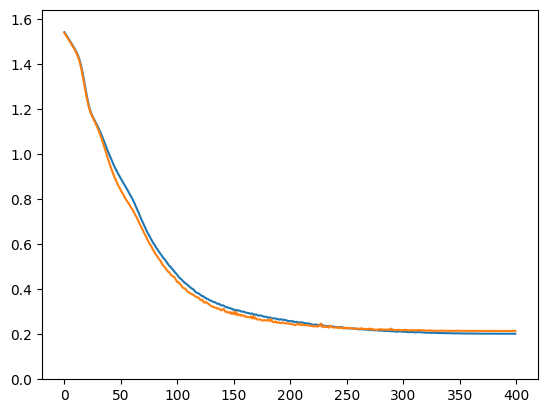

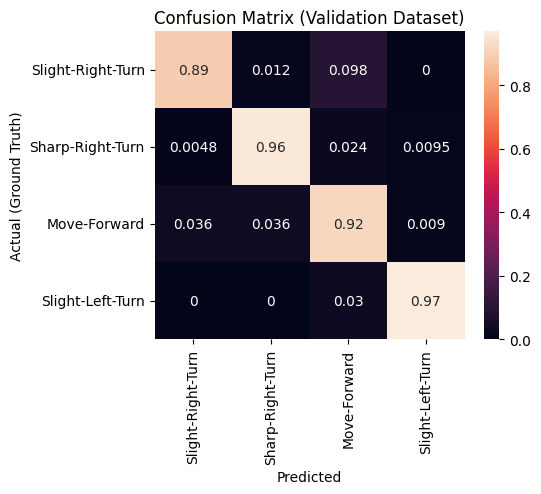

In [ ]:

# instantiate the network
model = RobotMoveModel(n_feat = X.shape[-1], n_out = len(classnames))

# move the model to the appropriate device
model = model.to(device)

# start training and validation
train_loop(model, train_dataloader, valid_dataloader, epochs=400, lr=0.0004, wd=0.00001, max_patience = 10, class_weights = None) #update this as well(patiance) defulat 10,5 is shorter and 15 for longer

Performance on the Test set (Use for reporting purposes only)

In [ ]:
preds = []
total = 0
correct = 0

model.eval()

with torch.no_grad():
    for x ,y in test_dataloader:
        x, y = x.cuda(), y.cuda()
        current_batch_size = y.shape[0]
        total += current_batch_size
        out = model(x.float())
        pred = torch.argmax(out, axis = 1)
        correct += (pred == y).float().sum().item()

        prob = F.softmax(out, dim=1)
        preds.append(prob)

print(f'Test accuracy: {correct/total}')

Test accuracy: 0.9102564102564102
